# JPEG coefficients → a smooth encoded photograph

## Problem
The task recovers a centered luminance/chroma field from a real compressed photograph. Quantized DCT coefficients specify intervals, not a unique original image. We therefore evaluate the public **TV-plus-coefficient criterion and every interval**, rather than pretend an independently uncompressed photograph is known. All 432 coded rows are reconstructed; the physical display has 427 rows.

The selected method is the author's native first-order TV branch (`w=0`). A separate original TV2 reconstruction is retained as a diagnostic because an independent finite-difference check exposed an upstream boundary-gradient defect. No corrected TV2 implementation is presented as an unchanged reproduction.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_observations
from src.physics_model import inverse,transform,objective
from src.solvers import reconstruct
from src.visualization import rgb_preview,comparison_figure
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold'})
a,q=load_observations(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream.npz') as z:
    original50=z['tv50'].copy();diagnostic_tv2=z['tv2_diagnostic'].copy()
with np.load(root/'evaluation/baseline_reference.npz') as z:original2000=z['reconstruction'][0].copy()
midpoint=inverse(a*q.astype(np.float32)[:,None,None])
print('Observed arrays:',a.shape,a.dtype,q.shape,q.dtype)
print('Coded unknown:',midpoint.shape,'physical display:',rgb_preview(midpoint).shape)


Observed arrays: (3, 54, 80, 8, 8) int16 (3, 8, 8) uint16
Coded unknown: (3, 432, 640) physical display: (427, 640, 3)


## Data
The observation is an existing public-domain SpaceX DSCOVR launch JPEG, reused without recompression or added noise. Stored integers and quantization steps retain their native signed-int16 and unsigned-uint16 precision. All channels are sampled at full resolution (4:4:4). The spatially varying integer coefficients and frequency-dependent quantization steps are both measurements/calibration available to a solver; reconstructed images are private comparison material.

The following plot shows the observation's ordinary inverse-DCT representative and its actual frequency quantization tables. It is an observable midpoint reconstruction, **not ground truth**.

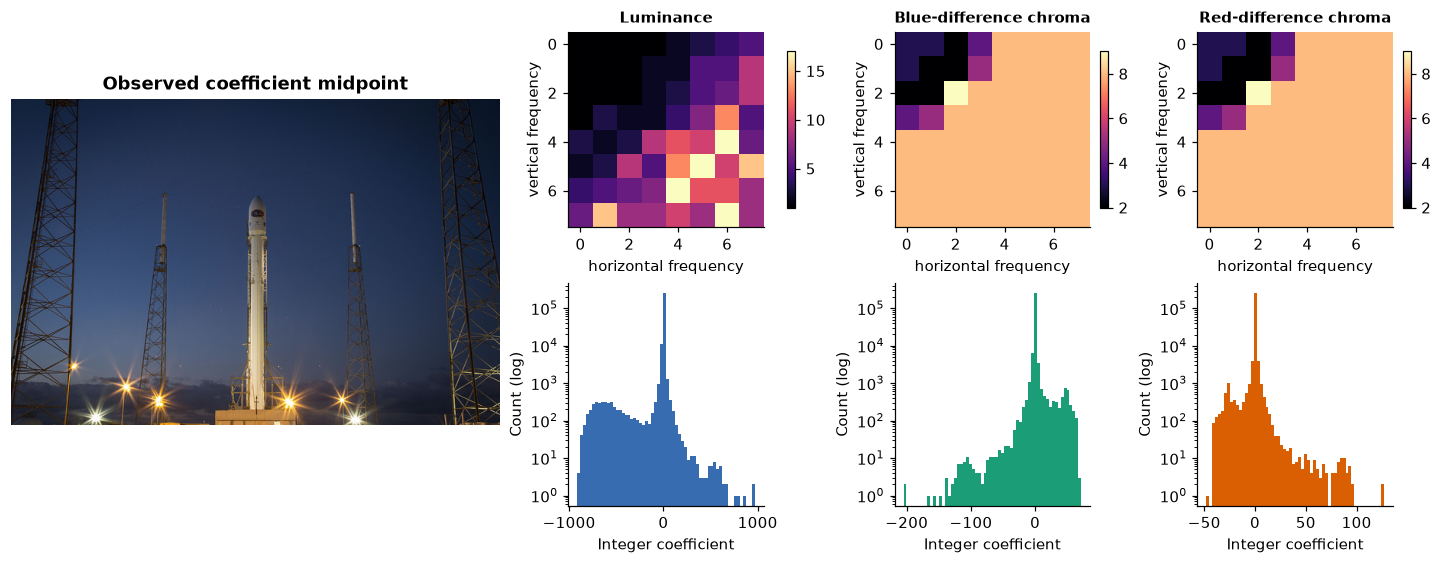

In [2]:
fig=plt.figure(figsize=(13,5),layout='constrained')
gs=fig.add_gridspec(2,4,width_ratios=[2.5,1,1,1])
ax=fig.add_subplot(gs[:,0]);ax.imshow(rgb_preview(midpoint));ax.set_title('Observed coefficient midpoint');ax.axis('off')
for c,label in enumerate(['Luminance','Blue-difference chroma','Red-difference chroma']):
    ax=fig.add_subplot(gs[0,c+1]);im=ax.imshow(q[c],cmap='magma');ax.set_title(label,fontsize=10);ax.set_xlabel('horizontal frequency');ax.set_ylabel('vertical frequency');fig.colorbar(im,ax=ax,shrink=.7)
    ax=fig.add_subplot(gs[1,c+1]);values=a[c].ravel();ax.hist(values,bins=60,color=['#386cb0','#1b9e77','#d95f02'][c],log=True);ax.set_xlabel('Integer coefficient');ax.set_ylabel('Count (log)')
plt.show()


## Physics and inverse model
For every 8×8 block, the orthonormal DCT $D$ maps the centered intensity field $u$ to coefficients. Observed integer $a$ and positive step $q$ imply $q(a-1/2)\leq Du\leq q(a+1/2)$. No gain, phase or geometric alignment is available or fitted.

The public criterion is $J(u)=\mathrm{TV}(u)/\sqrt3+\alpha\| (Du-aq)/q\|^2/2$, with $\alpha=0.001\,2\,255\sqrt2$. Here TV sums the joint Euclidean norm of all three channels' horizontal/vertical forward differences, with zero outgoing faces. The padded rows participate in both terms. The output stays in centered encoded intensity units; RGB conversion and clipping are solely display operations.

## Method
The reference initializes at the coefficient midpoint, uses the original accelerated normalized-subgradient updates, and projects each iterate back into all measured DCT intervals. The standard numerical reconstruction uses 2000 updates. The evaluator independently checks the public objective and interval constraints; it never scores identity with those particular iterates.

The next cell actively computes both fresh runs using only the cleaned local modules. No archived reconstruction is loaded as a fresh result.

In [3]:
started=time.perf_counter()
fresh50=reconstruct(a,q,iterations=50)
short_runtime=time.perf_counter()-started
started=time.perf_counter()
fresh=reconstruct(a,q,iterations=2000)
runtime=time.perf_counter()-started
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
print(f'Fresh 50-update run: {short_runtime:.3f} s; fresh complete 2000-update run: {runtime:.3f} s')
print(json.dumps(report,indent=2));assert exit_code==0


Fresh 50-update run: 2.636 s; fresh complete 2000-update run: 118.063 s
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "objective": 1069560.9183407857,
    "coefficient_violation": 6.866455066756316e-05
  },
  "thresholds": {
    "objective": {
      "comparison": "<=",
      "boundary": 1069668.9353281092
    },
    "coefficient_violation": {
      "comparison": "<=",
      "boundary": 0.001
    }
  },
  "errors": []
}


## Results
The four panels distinguish the measured midpoint, the newly computed local TV result, the independently executed original TV result and the actually executed original TV2 diagnostic. These are method comparisons, not comparisons to an unobserved true photograph. The original TV2 panel uses 50 updates and a different criterion; it is retained to expose the upstream boundary problem, not to claim superior or matched performance.

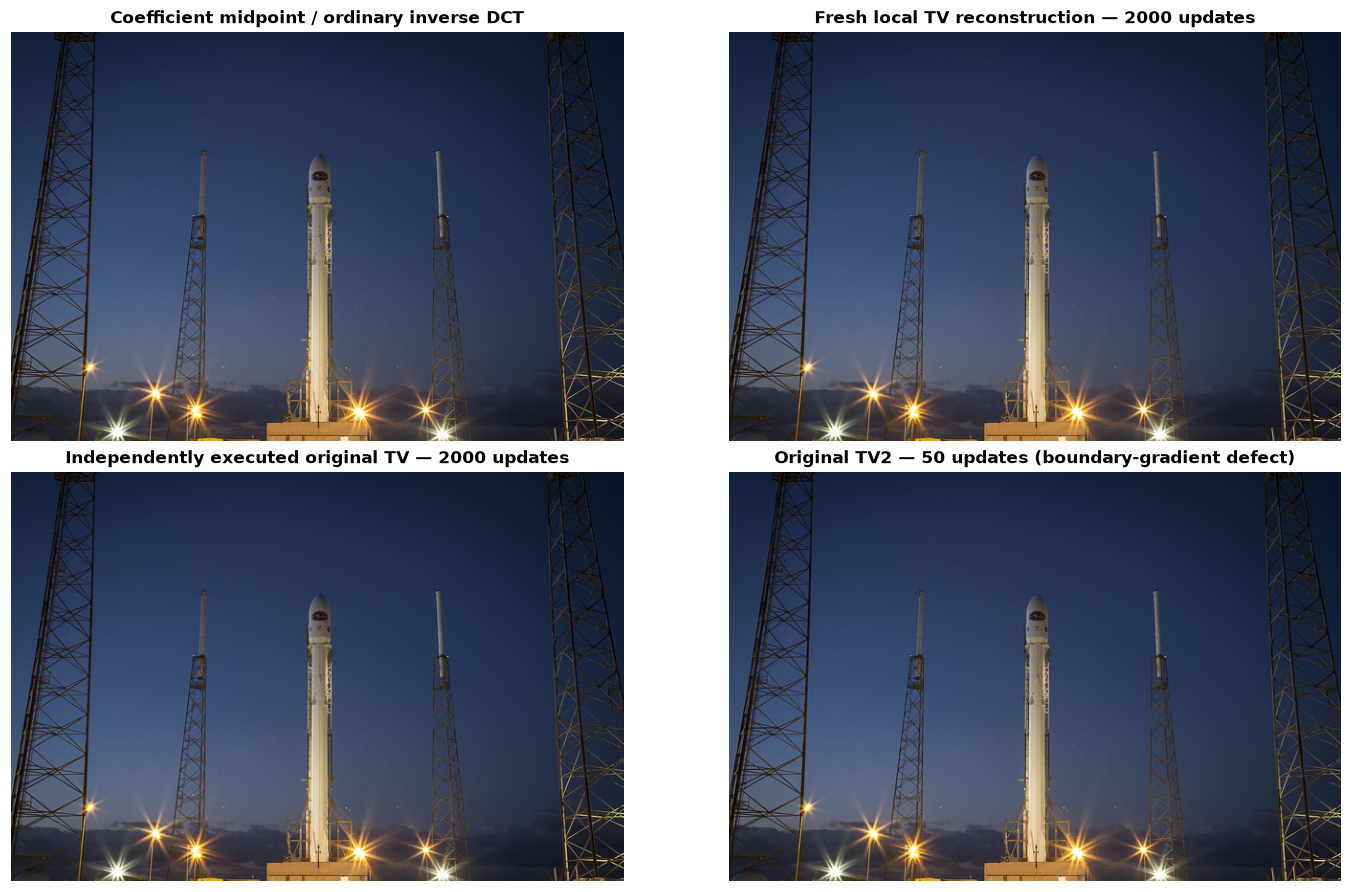

[
  {
    "method": "Midpoint",
    "objective": 1338936.4247180317,
    "coefficient_violation": 0.0
  },
  {
    "method": "Original TV50",
    "objective": 1072195.2350630593,
    "coefficient_violation": 4.196166980818816e-05
  },
  {
    "method": "Fresh TV50",
    "objective": 1072197.1035155554,
    "coefficient_violation": 7.629394519881316e-05
  },
  {
    "method": "Original TV2000",
    "objective": 1069561.9721799737,
    "coefficient_violation": 4.9591064453125e-05
  },
  {
    "method": "Fresh TV2000",
    "objective": 1069560.9183407857,
    "coefficient_violation": 6.866455066756316e-05
  }
]
Original/local RMS difference in encoded intensity units: 0.003586214698371803
Original/local RMS difference divided by 255: 1.4063587052438442e-05


In [4]:
fig=comparison_figure(midpoint,fresh,original2000,diagnostic_tv2)
plt.show()
labels=['Midpoint','Original TV50','Fresh TV50','Original TV2000','Fresh TV2000']
arrays=[midpoint,original50,fresh50,original2000,fresh]
measurements=[]
for label,u in zip(labels,arrays):
    result=judge.score(u,a,q)
    measurements.append({'method':label,**result})
print(json.dumps(measurements,indent=2))
parity_rms=float(np.sqrt(np.mean((fresh-original2000).astype(float)**2)))
print('Original/local RMS difference in encoded intensity units:',parity_rms)
print('Original/local RMS difference divided by 255:',parity_rms/255)


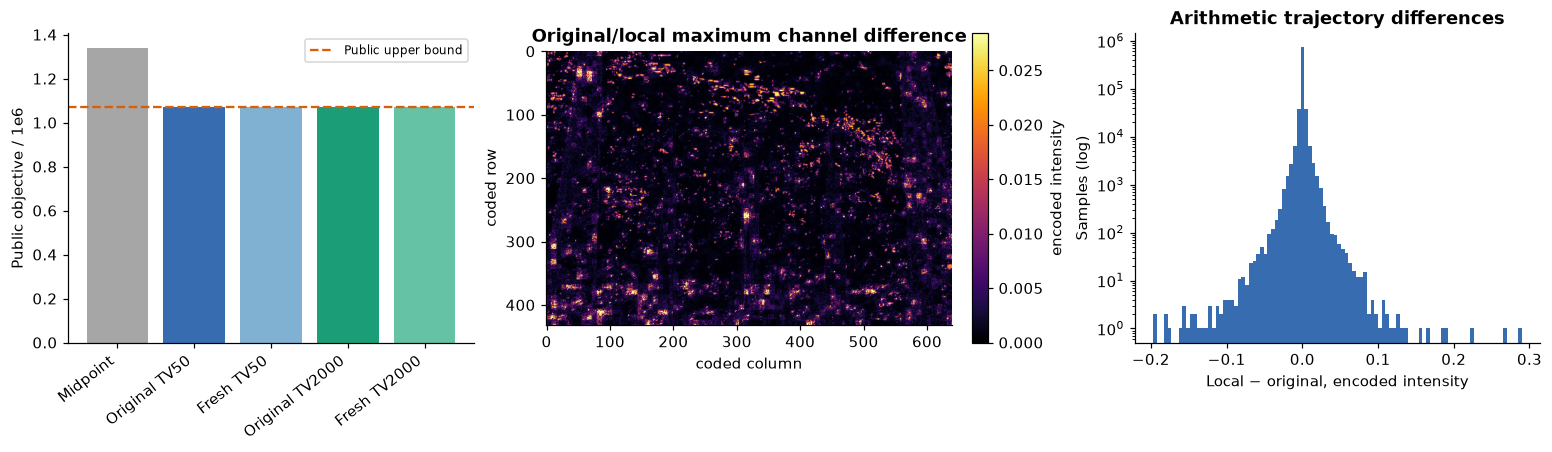

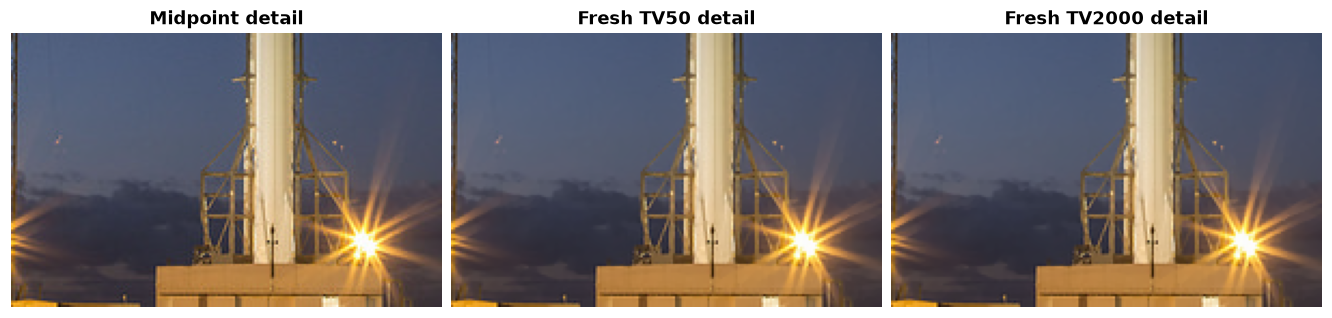

In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
colors=['#a6a6a6','#386cb0','#80b1d3','#1b9e77','#66c2a5']
axes[0].bar(np.arange(5),[m['objective']/1e6 for m in measurements],color=colors)
axes[0].axhline(report['thresholds']['objective']['boundary']/1e6,color='#d95f02',linestyle='--',label='Public upper bound')
axes[0].set_xticks(np.arange(5),labels,rotation=38,ha='right');axes[0].set_ylabel('Public objective / 1e6');axes[0].legend(fontsize=8)
error=np.max(np.abs(fresh-original2000),axis=0)
im=axes[1].imshow(error,cmap='inferno',vmin=0,vmax=max(.02,float(np.quantile(error,.995))));axes[1].set_title('Original/local maximum channel difference');axes[1].set_xlabel('coded column');axes[1].set_ylabel('coded row');fig.colorbar(im,ax=axes[1],label='encoded intensity')
axes[2].hist((fresh-original2000).ravel(),bins=100,color='#386cb0',log=True);axes[2].set_xlabel('Local − original, encoded intensity');axes[2].set_ylabel('Samples (log)');axes[2].set_title('Arithmetic trajectory differences')
plt.show()
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,u,label in zip(axes,[midpoint,fresh50,fresh],['Midpoint detail','Fresh TV50 detail','Fresh TV2000 detail']):
    ax.imshow(rgb_preview(u)[300:427,200:400]);ax.set_title(label);ax.axis('off')
plt.show()


## Independent checks and upstream discrepancy
Independent tests verify orthonormal DCT constants, the transform/transpose identity, zero-gradient constants and finite-difference TV gradients including boundaries. Original-C stage arrays independently check decoding and the gradient at the exact same full input; the tests also compare a complete fresh reconstruction with the original run using predeclared scale-aware RMS and objective tolerances.

For the original TV2 branch, the nondegenerate analytic 3×4 test image `[[0,2,1,5],[3,1,7,2],[4,8,3,6]]` gives maximum boundary derivative error 2.0168058630 against independent central finite differences (epsilon 1e-5), while interior error is below 1e-9. A private compiled original-C capture confirms the erroneous stencil numerically. It was not silently corrected in the selected method. This explains choosing the original program's supported TV branch.

## Conclusion
The fresh complete reconstruction satisfies the public coefficient intervals and mathematical objective bound. Its close numerical agreement with independent original execution verifies the extraction within documented float32 transform/arithmetic tolerances. The result is a regularized decoding representative; it does not establish the exact uncompressed camera image or absolute physical radiance. Fine texture and within-bin intensity remain limited by the original measurement information.

In [6]:
summary={'fresh_runtime_seconds':runtime,'fresh_short_runtime_seconds':short_runtime,'parity_rms_intensity':parity_rms,'parity_rms_over_255':parity_rms/255,'measurements':measurements,'judge':report}
print(json.dumps(summary,indent=2))


{
  "fresh_runtime_seconds": 118.06269789999351,
  "fresh_short_runtime_seconds": 2.635930799995549,
  "parity_rms_intensity": 0.003586214698371803,
  "parity_rms_over_255": 1.4063587052438442e-05,
  "measurements": [
    {
      "method": "Midpoint",
      "objective": 1338936.4247180317,
      "coefficient_violation": 0.0
    },
    {
      "method": "Original TV50",
      "objective": 1072195.2350630593,
      "coefficient_violation": 4.196166980818816e-05
    },
    {
      "method": "Fresh TV50",
      "objective": 1072197.1035155554,
      "coefficient_violation": 7.629394519881316e-05
    },
    {
      "method": "Original TV2000",
      "objective": 1069561.9721799737,
      "coefficient_violation": 4.9591064453125e-05
    },
    {
      "method": "Fresh TV2000",
      "objective": 1069560.9183407857,
      "coefficient_violation": 6.866455066756316e-05
    }
  ],
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "objective": 1069560.9183407857,
    